In [2]:
import numpy as np

In [11]:
import os

In [3]:
h,w = 3040,4056

In [4]:
g_cx,g_cy = 2027.5,1419.5
u_cx,u_cy=2187.5,1519.5
g_half= 687.6750000000001*475/390
u_half =687.6750000000001
def make_square_mask_from_center(h, w, cx, cy, half):
    mask = np.zeros((h, w), dtype=np.uint8)

    x0 = int(max(cx - half, 0))
    x1 = int(min(cx + half, w))
    y0 = int(max(cy - half, 0))
    y1 = int(min(cy + half, h))

    mask[y0:y1, x0:x1] = 1
    return mask
g_mask = make_square_mask_from_center(h, w, g_cx, g_cy, g_half)
uv_mask = make_square_mask_from_center(h, w, u_cx, u_cy, u_half)

In [5]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'UV mask: 1376.0')

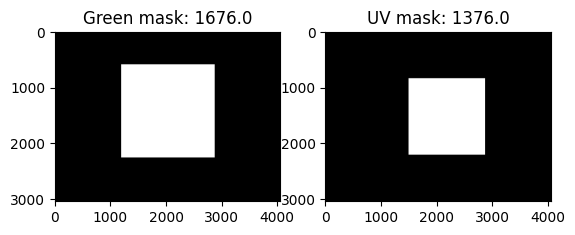

In [6]:
plt.subplot(121)
plt.imshow(g_mask,cmap='gray')
plt.title(f"Green mask: {np.sqrt(np.sum(g_mask))}")
plt.subplot(122)
plt.imshow(uv_mask,cmap='gray')
plt.title(f"UV mask: {np.sqrt(np.sum(uv_mask))}")

In [7]:
cam0_path ='./cam0/'
cam1_path ='./cam1/'

In [8]:
import glob

In [15]:
for cam in ['cam0','cam1']:
    cam_path = f'./{cam}/'
    if 'cam0' in cam_path:
        ys, xs = np.where(g_mask == 1)

        y_min, y_max = ys.min(), ys.max() + 1
        x_min, x_max = xs.min(), xs.max() + 1
    else:
        ys, xs = np.where(uv_mask == 1)

        y_min, y_max = ys.min(), ys.max() + 1
        x_min, x_max = xs.min(), xs.max() + 1
    for z_loc in ['ground','sky']:
        npys_dir = os.path.join(cam_path,f"{z_loc}_npys/")
        all_npys = glob.glob(os.path.join(npys_dir,f"*.npy"))
        print(npys_dir)
        f_name = all_npys[0].split('/')[-1].replace('.npy','')[:-2]
        for ii in range(len(all_npys)-1,-1,-1):
            tmp_full_npy_path = os.path.join(npys_dir,f'{f_name}_{ii}.npy')
            if os.path.exists(tmp_full_npy_path):
                cropped_img = np.load(tmp_full_npy_path)[y_min:y_max, x_min:x_max]
                print(f'cropping {tmp_full_npy_path}')
                print(cropped_img.shape)
                np.save(f'{npys_dir}{cam}_{ii}.npy',cropped_img)
                #break

./cam0/ground_npys/
cropping ./cam0/ground_npys/cam0_gain8_1000ms_11.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_10.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_9.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_8.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_7.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_6.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_5.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_4.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_3.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_2.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_1.npy
(1676, 1676)
cropping ./cam0/ground_npys/cam0_gain8_1000ms_0.npy
(1676, 1676)
./cam0/sky_npys/
cropping ./cam0/sky_npys/cam0_gain1.12_300ms_11.npy
(1676, 1676)
cropping ./cam0/sky_npys/cam0_gain1.12_300ms_10.npy
(1676, 1676)
cropping ./cam0/sky_npys/cam0_gain1.12_300ms_9.npy


In [23]:
all_npys[0]

'./cam0/ground_npys/cam0_gain8_1000ms_4.npy'

In [ ]:
cropped_uv_img = uv_imgs[-1][y_min:y_max, x_min:x_max]
for ii in range(len(uv_imgs)):
    tmp_crop = uv_imgs[ii][y_min:y_max, x_min:x_max]
    print(tmp_crop.shape)
    break

In [11]:
import os

In [13]:
os.listdir(cam0_path)

['ground_npys.zip', 'ground_npys', 'sky_npys.zip', 'sky_npys']